In [1]:
"""
Linear Regression in Code: Multiple Linear Regression

@author:   Oscar Trevizo
@created:  November 16, 2026
@playlist: https://www.youtube.com/playlist?list=PLJgpRhj3_bvHVST9GVlT3_Su01bp_brLu
@data:     Synthetic: 50 points (y, var1, var2) with a fixed random seed

Two predictors, one model, y ~ var1 + var2: fit, predict, score
(R-squared), coef_ and intercept_ on a train / test split.
Built on camera in Google Colab.
"""

'\nLinear Regression in Code: Multiple Linear Regression\n\n@author:   Oscar Trevizo\n@created:  November 16, 2026\n@playlist: https://www.youtube.com/playlist?list=PLJgpRhj3_bvHVST9GVlT3_Su01bp_brLu\n@data:     Synthetic: 50 points (y, var1, var2) with a fixed random seed\n\nTwo predictors, one model, y ~ var1 + var2: fit, predict, score\n(R-squared), coef_ and intercept_ on a train / test split.\nBuilt on camera in Google Colab.\n'

In [2]:
# --- Libraries: toolboxes other people wrote ---
import pandas as pd                # tables (DataFrames)
import numpy as np                 # math and random numbers
import seaborn as sns              # charts
import matplotlib.pyplot as plt    # basic plotting

# scikit-learn (written sklearn in code): Python's main machine-learning library.
# From two of its modules, we import two tools:
from sklearn.model_selection import train_test_split    # a FUNCTION: splits data into train / test
from sklearn.linear_model import LinearRegression       # a CLASS: the blueprint for a regression model

sns.set_style("darkgrid")

In [3]:
# --- Data: the same 50 points as video 1 ---
# The seed makes the "random" noise the same every run,
# so everyone gets the same results
np.random.seed(42)

# Each variable = a straight trend from 0 to 100 (50 evenly spaced points)
#               + random noise from a normal distribution.
# np.random.normal(scale=SD, size=50): 50 random values with mean 0 and
# standard deviation SD. A larger SD scatters the points farther from the trend.
y    = np.linspace(0, 100, 50) + np.random.normal(scale=15, size=50)    # target: noise SD = 15
var1 = np.linspace(0, 100, 50) + np.random.normal(scale=20, size=50)    # noise SD = 20 (noisier)
var2 = np.linspace(0, 100, 50) + np.random.normal(scale=10, size=50)    # noise SD = 10 (less noisy)

# Put the three columns into one table
df = pd.DataFrame({'y': y, 'var1': var1, 'var2': var2})

In [4]:
# --- Train / test split (from video 2) ---
# X = predictors (the inputs we learn from): var1 and var2
# y = target (the answer we want to predict). y stays OUT of X.
X = df[['var1', 'var2']]

# Shuffle the 50 rows, then split them into training and test sets.
# train_test_split returns FOUR pieces, named on the left of the = sign:
#   x_train, y_train -> 40 rows the model learns from (inputs and answers)
#   x_test,  y_test  -> 10 rows held back to check the model (inputs and answers)
x_train, x_test, y_train, y_test = train_test_split(
    X,                  # predictors
    y,                  # target
    test_size=0.2,      # 20% of rows go to the test set
    random_state=40,    # same shuffle every run
)

## Multiple linear regression

One target (y), two predictors (var1 and var2). In the lecture this was called *multivariate* regression.

In [5]:
multiple_lr = LinearRegression()
multiple_lr.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[0.36,0.58]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['var1','var2']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.7127
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,2


In [6]:
multiple_y_predict = multiple_lr.predict(x_test)

multiple_lr_r2 = multiple_lr.score(x_test, y_test)
multiple_lr_r2

0.716098782406934

In [7]:
multiple_lr.coef_

array([0.35667069, 0.57949821])

In [8]:
multiple_lr.intercept_

np.float64(0.712673381113305)

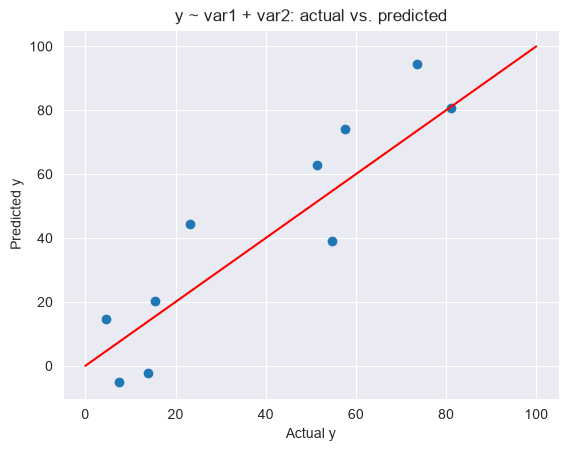

In [9]:
plt.scatter(y_test, multiple_y_predict)
plt.plot([0, 100], [0, 100], color='red')   # perfect-prediction line
plt.xlabel('Actual y')
plt.ylabel('Predicted y')
plt.title('y ~ var1 + var2: actual vs. predicted')
plt.show()